# inD Dataset – Data Cleaning

Identifies unrealistic vehicle tracks and produces `tracks_clean.csv`.

## Imports and Configuration

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR        = Path("inD-dataset-v1.1/data")
VEHICLE_CLASSES = ["car", "truck_bus"]

# ── Thresholds ────────────────────────────────────────────────────────────────
MIN_PATH_M         = {1: 35.0, 2: 39.0, 3: 49.0, 4: 54.0}  # observed minimum crossing path per location (m)
CLEAN_FACTOR       = 0.90    # flag tracks below this fraction of the location minimum
STATIC_PATH_M      = 2.0     # tracks below this are considered stationary and dropped immediately
PLAUSIBLE_LENGTH_M = {"car": (3.0, 6.0), "truck_bus": (5.5, 20.0)}
PLAUSIBLE_WIDTH_M  = {"car": (1.5, 2.5), "truck_bus": (2.0,  3.6)}
MIN_PREV_STEP_M    = 0.10    # skip ratio when previous step was below this (m/frame ≈ 2.5 m/s = 9 km/h)
SPEED_SPIKE_RATIO  = 600     # flag if step[t] / step[t-1] * 100 exceeds this (600 = 6× previous step)

# ── Plot style ────────────────────────────────────────────────────────────────
CLASS_COLORS    = {"car": "#4a90d9", "truck_bus": "#e07b39"}
THRESHOLD_COLOR = "#c0392b"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white",
                     "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

# ── Load data ─────────────────────────────────────────────────────────────
recording_meta = pd.concat(
    [pd.read_csv(p) for p in sorted(DATA_DIR.glob("*_recordingMeta.csv"))],
    ignore_index=True,
)
tracks = pd.concat(
    [pd.read_csv(p) for p in sorted(DATA_DIR.glob("*_tracksMeta.csv"))],
    ignore_index=True,
)
tracks = (tracks[tracks["class"].isin(VEHICLE_CLASSES)]
          .merge(recording_meta[["recordingId", "locationId"]], on="recordingId")
          .reset_index(drop=True))

# ── Compute path length per track ─────────────────────────────────────────────
path_rows = []
for p in sorted(DATA_DIR.glob("*_tracks.csv")):
    recording_id = int(p.stem.split("_")[0])
    valid_ids    = tracks.loc[tracks["recordingId"] == recording_id, "trackId"]
    df = pd.read_csv(p, usecols=["trackId", "frame", "xCenter", "yCenter"])
    df = df[df["trackId"].isin(valid_ids)].sort_values(["trackId", "frame"])
    df["step"] = np.hypot(
        df.groupby("trackId")["xCenter"].diff(),
        df.groupby("trackId")["yCenter"].diff(),
    )
    path = df.groupby("trackId")["step"].sum().rename("path_m").reset_index()
    path.insert(0, "recordingId", recording_id)
    path_rows.append(path)

tracks = tracks.merge(
    pd.concat(path_rows, ignore_index=True),
    on=["recordingId", "trackId"], validate="one_to_one",
)

# ── Drop static tracks before any further processing ─────────────────────────
n_static = (tracks["path_m"] < STATIC_PATH_M).sum()
tracks = tracks[tracks["path_m"] >= STATIC_PATH_M].reset_index(drop=True)
print(f"Static tracks removed : {n_static:,}")

THRESHOLD_PATH_M         = {loc: CLEAN_FACTOR * val for loc, val in MIN_PATH_M.items()}
tracks["threshold_path"] = tracks["locationId"].map(THRESHOLD_PATH_M)

print(f"{len(tracks):,} vehicle tracks  |  "
      f"car: {(tracks['class']=='car').sum():,}  "
      f"truck_bus: {(tracks['class']=='truck_bus').sum():,}")

## 1 · Short Path

For each location the minimum distance to fully cross the intersection was measured. Tracks shorter than `0.9 × MIN_PATH_M` are removed.

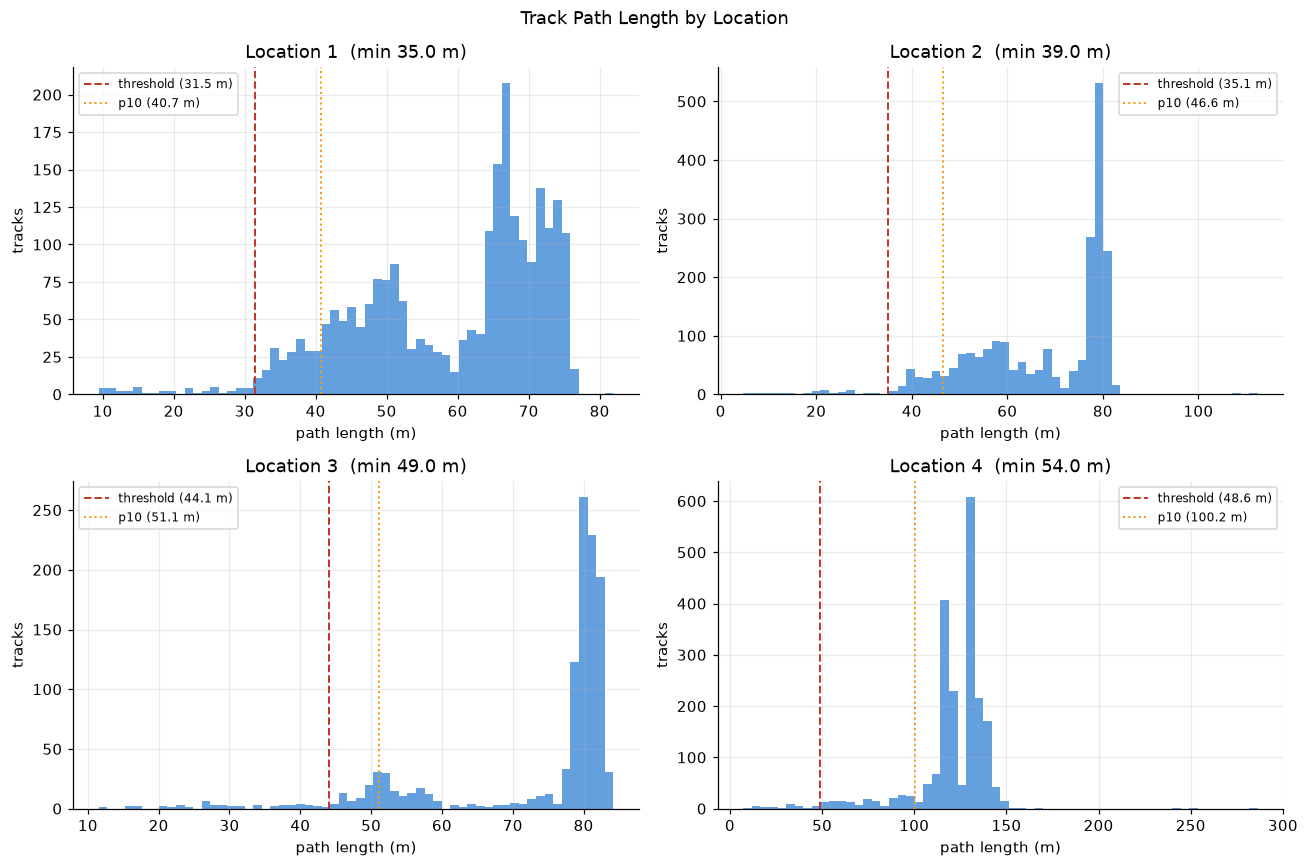

In [ ]:
LOCATIONS = sorted(MIN_PATH_M.keys())
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, loc in zip(axes.flat, LOCATIONS):
    values    = tracks.loc[tracks["locationId"] == loc, "path_m"]
    threshold = THRESHOLD_PATH_M[loc]
    p10 = values.quantile(0.10)
    ax.hist(values, bins=60, color="#4a90d9", alpha=0.85)
    ax.axvline(threshold, color=THRESHOLD_COLOR, linestyle="--",
               linewidth=1.3, label=f"threshold ({threshold:.1f} m)")
    ax.axvline(p10, color="#f39c12", linestyle=":",
               linewidth=1.3, label=f"p10 ({p10:.1f} m)")
    ax.set_title(f"Location {loc}  (min {MIN_PATH_M[loc]} m)")
    ax.set_xlabel("path length (m)"); ax.set_ylabel("tracks")
    ax.legend(fontsize=8)
fig.suptitle("Track Path Length by Location"); fig.tight_layout(); plt.show()

In [ ]:
tracks["flag_short_path"] = tracks["path_m"] < tracks["threshold_path"]

n = tracks["flag_short_path"].sum()
print(f"short paths flagged: {n:,} tracks ({100 * n / len(tracks):.1f}%)")

short paths flagged: 184 tracks (2.3%)


## 2 · Bounding Box Dimensions

Plausible length and width ranges were defined per vehicle class. Tracks outside those bounds are removed.

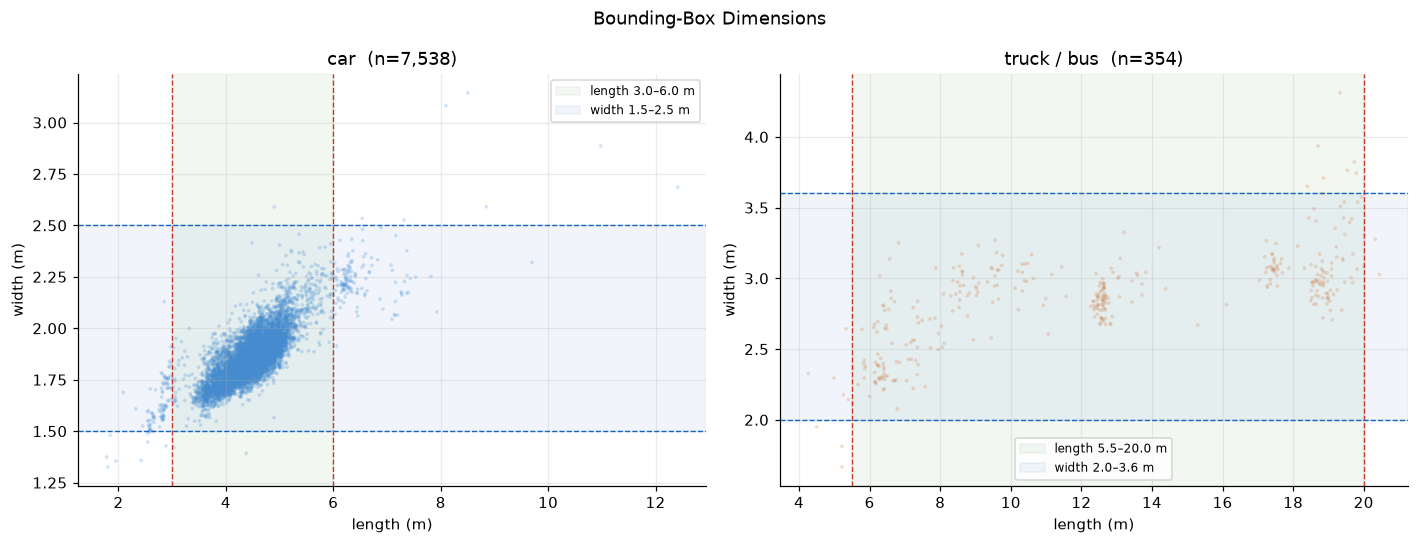

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cls in zip(axes, VEHICLE_CLASSES):
    subset     = tracks[tracks["class"] == cls]
    lo_l, hi_l = PLAUSIBLE_LENGTH_M[cls]
    lo_w, hi_w = PLAUSIBLE_WIDTH_M[cls]
    ax.scatter(subset["length"], subset["width"],
               s=6, alpha=0.25, color=CLASS_COLORS[cls], edgecolors="none")
    ax.axvspan(lo_l, hi_l, alpha=0.06, color="#2e7d32", label=f"length {lo_l}–{hi_l} m")
    ax.axhspan(lo_w, hi_w, alpha=0.06, color="#1565c0", label=f"width {lo_w}–{hi_w} m")
    for v in [lo_l, hi_l]: ax.axvline(v, color=THRESHOLD_COLOR, ls="--", lw=0.9)
    for v in [lo_w, hi_w]: ax.axhline(v, color="#1565c0",       ls="--", lw=0.9)
    ax.set_title(f"{cls.replace('_', ' / ')}  (n={len(subset):,})")
    ax.set_xlabel("length (m)"); ax.set_ylabel("width (m)"); ax.legend(fontsize=8)
fig.suptitle("Bounding-Box Dimensions"); fig.tight_layout(); plt.show()

In [ ]:
tracks["flag_length_implaus"] = ~tracks.apply(
    lambda r: PLAUSIBLE_LENGTH_M[r["class"]][0] <= r["length"] <= PLAUSIBLE_LENGTH_M[r["class"]][1], axis=1)
tracks["flag_width_implaus"]  = ~tracks.apply(
    lambda r: PLAUSIBLE_WIDTH_M[r["class"]][0]  <= r["width"]  <= PLAUSIBLE_WIDTH_M[r["class"]][1],  axis=1)

n_l = tracks["flag_length_implaus"].sum()
n_w = tracks["flag_width_implaus"].sum()
print(f"flag_length_implaus: {n_l:,} ({100 * n_l / len(tracks):.1f}%)")
print(f"flag_width_implaus:  {n_w:,} ({100 * n_w / len(tracks):.1f}%)")

flag_length_implaus: 244 (3.1%)
flag_width_implaus:  32 (0.4%)


## 3 · Teleportation

To detect potential teleportation, we examined speed changes between consecutive bounding boxes by computing the ratio `step[t] / step[t−1] × 100` for each frame and plotting its distribution. A genuine tracker jump would appear as a sudden large ratio.

Frames where `step[t−1] < MIN_PREV_STEP_M` (0.10 m/frame ≈ 9 km/h) are skipped: at low speeds the inD position error of < 0.1 m per frame makes up a large fraction of the step, making the ratio too prone to noise-driven spikes. A track is flagged if any qualifying frame exceeds `SPEED_SPIKE_RATIO`.

**Why no teleportation was found:** the highest ratio in the dataset is 135.3, implying an apparent 35% speed increase in a single frame (Δt = 1/25 s). At our minimum qualifying speed (0.10 m/frame), this corresponds to:

- Δv = 0.35 × 0.10 m/frame × 25 Hz = 0.88 m/s
- a = Δv / Δt = 0.88 / 0.04 s = **22 m/s² (~2.2g)**

This apparent acceleration is not real motion but a measurement artefact. The inD dataset specifies a position error of < 0.1 m per frame, which for a minimum qualifying step of 0.10 m produces an apparent displacement variation of ±100%. The observed maximum of 35% falls well within that noise envelope. A genuine tracker jump — where the bounding box centre shifts by several metres in a single frame — would produce ratios in the hundreds or thousands, far above `SPEED_SPIKE_RATIO`. No such events are present in this dataset.

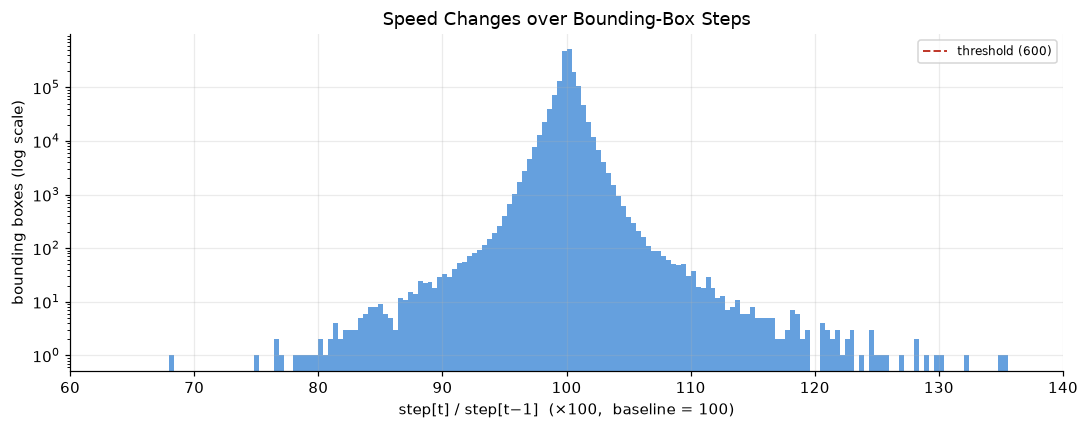

In [ ]:
ratio_rows = []

for p in sorted(DATA_DIR.glob("*_tracks.csv")):
    rec_id    = int(p.stem.split("_")[0])
    valid_ids = tracks.loc[tracks["recordingId"] == rec_id, "trackId"]
    df = pd.read_csv(p, usecols=["trackId", "frame", "xCenter", "yCenter"])
    df = df[df["trackId"].isin(valid_ids)].sort_values(["trackId", "frame"])
    df["step"] = np.hypot(
        df.groupby("trackId")["xCenter"].diff(),
        df.groupby("trackId")["yCenter"].diff(),
    )
    df["prev_step"] = df.groupby("trackId")["step"].shift(1)
    mask = df["prev_step"] > MIN_PREV_STEP_M
    df.loc[mask, "ratio_pct"] = df["step"] / df["prev_step"] * 100
    df.insert(0, "recordingId", rec_id)
    ratio_rows.append(
        df[["recordingId", "trackId", "frame", "ratio_pct"]].dropna(subset=["ratio_pct"])
    )

ratios = pd.concat(ratio_rows, ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(ratios["ratio_pct"], bins=200, color="#4a90d9", alpha=0.85, range=(60, 140))
ax.axvline(SPEED_SPIKE_RATIO, color=THRESHOLD_COLOR, linestyle="--", linewidth=1.3,
           label=f"threshold ({SPEED_SPIKE_RATIO})")
ax.set_xlim(60, 140)
ax.set_yscale("log")
ax.set_xlabel("step[t] / step[t−1]  (×100,  baseline = 100)")
ax.set_ylabel("bounding boxes (log scale)")
ax.set_title("Speed Changes over Bounding-Box Steps")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Export

Combine all flags, write the cleaned track list, then assemble a training-ready dataframe joined with recording metadata.

In [ ]:
FLAG_COLS = ["flag_short_path", "flag_length_implaus", "flag_width_implaus"]

tracks_clean = tracks[~tracks[FLAG_COLS].any(axis=1)].drop(columns=FLAG_COLS + ["threshold_path"])

n_removed = len(tracks) - len(tracks_clean)
print(f"Removed : {n_removed:,} of {len(tracks):,} tracks ({100 * n_removed / len(tracks):.1f}%)")
print(f"Kept    : {len(tracks_clean):,}")

tracks_clean.to_csv("tracks_clean.csv", index=False)
print("Written : tracks_clean.csv")

# ── Training-ready dataframe ──────────────────────────────────────────────────
training = tracks_clean.merge(recording_meta, on=["recordingId", "locationId"])

print(f"\nTraining set: {len(training):,} tracks  "
      f"· {training['recordingId'].nunique()} recordings  "
      f"· {training['locationId'].nunique()} locations")
print(training.groupby(["locationId", "class"]).size().rename("n_tracks")
      .reset_index().to_string(index=False))